<a href="https://colab.research.google.com/github/AndreaFreemanfse/Flatiron/blob/main/Promp_Engineering_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prompt

I have the following Python function that is not behaving as expectd:

```
def analyze_user_engagement(logs_df):
    metrics = {
        'bounce_rate': logs_df.groupby('session_id')['page_views'].apply(
            lambda x: x == 1).mean(),
        'avg_session_time': logs_df.groupby('session_id')['duration'].sum(),
        'pages_per_session': logs_df.groupby('session_id')['page_views'].mean()
    }
    
    device_metrics = logs_df.groupby('device_type').agg({
        'session_id': 'count',
        'duration': 'mean',
        'page_views': 'sum'
    })
    
    return metrics, device_metrics
```

Analyze the code for errors.

The code should:
- Write a complete, copy-and-paste-ready Python solution for analyzing user engagement using Pandas and NumPy.

Requirements:
- Include realistic sample data so the code runs independently.
- Calculate overall engagement metrics, including bounce rate, average session duration, average page views, and total sessions.
- Calculate device-level engagement metrics grouped by device type.
- Include clear comments explaining each step.
- Add basic validation checks for missing columns, null values, duplicate session IDs, invalid numeric values, negative session durations, and invalid page counts.
- Handle errors with meaningful error messages.
- Return the overall metrics as a dictionary and device-level metrics as a Pandas DataFrame.
- Include a runnable `if __name__ == "__main__":` block that executes the function and prints the results.
- Round appropriate metrics for readability and display bounce rates as percentages.
- Do not modify the original input DataFrame.
- Explain any assumptions, especially the definition of a bounced session.
- Include installation instructions for required libraries.

Return the entire solution as one complete Python code block that can be copied, saved, and executed without additional code.

# Response

In [2]:

import pandas as pd
import numpy as np


def analyze_user_engagement(logs_df):
    """
    Analyze user engagement using session-level data.

    Parameters
    ----------
    logs_df : pandas.DataFrame
        Must contain:
        - session_id: Unique identifier for each session
        - page_views: Number of pages viewed in a session
        - session_time: Session duration in seconds
        - device_type: Device used during the session

    Returns
    -------
    tuple
        metrics: Dictionary of overall engagement metrics.
        device_metrics: DataFrame of engagement metrics by device.
    """

    # --------------------------------------------------
    # 1. Validate the input DataFrame
    # --------------------------------------------------

    if not isinstance(logs_df, pd.DataFrame):
        raise TypeError("logs_df must be a pandas DataFrame.")

    if logs_df.empty:
        raise ValueError("logs_df cannot be empty.")

    # Check that all required columns exist.
    required_columns = [
        "session_id",
        "page_views",
        "session_time",
        "device_type"
    ]

    missing_columns = [
        column for column in required_columns
        if column not in logs_df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {missing_columns}"
        )

    # Work on a copy so the original DataFrame is unchanged.
    logs_df = logs_df[required_columns].copy()

    # Check for missing values in required columns.
    if logs_df.isnull().any().any():
        raise ValueError(
            "Input data contains missing values in required columns."
        )

    # Ensure each row represents one unique session.
    if logs_df["session_id"].duplicated().any():
        raise ValueError(
            "Each session_id must be unique. "
            "Aggregate multiple rows per session before analysis."
        )

    # Ensure page views and session durations are numeric.
    for column in ["page_views", "session_time"]:
        logs_df[column] = pd.to_numeric(
            logs_df[column], errors="raise"
        )

        # Reject infinite or non-numeric values.
        if not np.isfinite(logs_df[column]).all():
            raise ValueError(
                f"{column} must contain finite numeric values."
            )

    # Page views must be positive whole numbers.
    if (
        (logs_df["page_views"] < 1).any()
        or not logs_df["page_views"].mod(1).eq(0).all()
    ):
        raise ValueError(
            "page_views must contain positive whole numbers."
        )

    # Session durations cannot be negative.
    if (logs_df["session_time"] < 0).any():
        raise ValueError(
            "session_time cannot contain negative values."
        )

    # Device types must be non-empty strings.
    if not logs_df["device_type"].map(
        lambda value: isinstance(value, str)
        and bool(value.strip())
    ).all():
        raise ValueError(
            "device_type must contain non-empty strings."
        )

    # --------------------------------------------------
    # 2. Calculate overall engagement metrics
    # --------------------------------------------------

    # A bounce is defined here as a session with one page view.
    # Mean of Boolean values gives the proportion of bounced sessions.
    bounce_rate = logs_df["page_views"].eq(1).mean()

    metrics = {
        "total_sessions": int(logs_df["session_id"].nunique()),
        "bounce_rate": float(bounce_rate),
        "bounce_rate_percent": float(bounce_rate * 100),
        "avg_session_time": float(
            logs_df["session_time"].mean()
        ),
        "avg_page_views": float(
            logs_df["page_views"].mean()
        )
    }

    # --------------------------------------------------
    # 3. Calculate engagement metrics by device
    # --------------------------------------------------

    device_metrics = (
        logs_df.groupby("device_type")
        .agg(
            total_sessions=("session_id", "nunique"),
            bounce_rate=(
                "page_views",
                lambda values: values.eq(1).mean()
            ),
            avg_session_time=("session_time", "mean"),
            avg_page_views=("page_views", "mean")
        )
        .reset_index()
    )

    # Convert device-level bounce rates to percentages.
    device_metrics["bounce_rate_percent"] = (
        device_metrics["bounce_rate"] * 100
    )

    # Round averages and rates for easier interpretation.
    device_metrics["bounce_rate"] = (
        device_metrics["bounce_rate"].round(3)
    )
    device_metrics["bounce_rate_percent"] = (
        device_metrics["bounce_rate_percent"].round(1)
    )
    device_metrics["avg_session_time"] = (
        device_metrics["avg_session_time"].round(2)
    )
    device_metrics["avg_page_views"] = (
        device_metrics["avg_page_views"].round(2)
    )

    return metrics, device_metrics


# ======================================================
# 4. Create sample data so the script runs independently
# ======================================================

logs_df = pd.DataFrame({
    "session_id": [101, 102, 103, 104, 105, 106, 107, 108],
    "page_views": [1, 3, 1, 5, 2, 1, 4, 2],
    "session_time": [15, 120, 10, 300, 90, 20, 240, 60],
    "device_type": [
        "Mobile",
        "Desktop",
        "Mobile",
        "Desktop",
        "Tablet",
        "Mobile",
        "Desktop",
        "Tablet"
    ]
})


# ======================================================
# 5. Run the analysis and display the results
# ======================================================

if __name__ == "__main__":
    try:
        metrics, device_metrics = analyze_user_engagement(
            logs_df
        )

        # Display the sample data.
        print("SAMPLE DATA")
        print(logs_df.to_string(index=False))

        # Display overall engagement metrics.
        print("\nOVERALL ENGAGEMENT METRICS")
        for metric, value in metrics.items():
            if metric == "bounce_rate":
                print(f"{metric}: {value:.3f}")
            elif metric == "bounce_rate_percent":
                print(f"{metric}: {value:.1f}%")
            elif isinstance(value, float):
                print(f"{metric}: {value:.2f}")
            else:
                print(f"{metric}: {value}")

        # Display engagement metrics for each device type.
        print("\nENGAGEMENT BY DEVICE")
        print(device_metrics.to_string(index=False))

    except (TypeError, ValueError) as error:
        print(f"Analysis error: {error}")


SAMPLE DATA
 session_id  page_views  session_time device_type
        101           1            15      Mobile
        102           3           120     Desktop
        103           1            10      Mobile
        104           5           300     Desktop
        105           2            90      Tablet
        106           1            20      Mobile
        107           4           240     Desktop
        108           2            60      Tablet

OVERALL ENGAGEMENT METRICS
total_sessions: 8
bounce_rate: 0.375
bounce_rate_percent: 37.5%
avg_session_time: 106.88
avg_page_views: 2.38

ENGAGEMENT BY DEVICE
device_type  total_sessions  bounce_rate  avg_session_time  avg_page_views  bounce_rate_percent
    Desktop               3          0.0             220.0             4.0                  0.0
     Mobile               3          1.0              15.0             1.0                100.0
     Tablet               2          0.0              75.0             2.0                

# Prompt Refinement

Include data-type checking. For example:

 Update "analyze_user_engagement(logs_df)" to validate that column names and session IDs are not blank, and that "page_views" contains only positive whole numbers, excluding Booleans. Preserve all existing validation, calculations, and return values. Include clear error messages and ensure the original DataFrame remains unchanged. Return the complete, copy-and-paste-ready Python script with comments and sample data. Also implement proper time calculations and create a summary visualization.

# Prompt Refinement Response

SAMPLE DATA WITH CALCULATED DURATIONS
 session_id device_type  session_time  page_views
        101      Mobile          15.0           1
        102     Desktop         120.0           3
        103      Mobile          10.0           1
        104     Desktop         300.0           5
        105      Tablet          90.0           2
        106      Mobile          20.0           1
        107     Desktop         240.0           4
        108      Tablet          60.0           2

OVERALL ENGAGEMENT METRICS
total_sessions: 8
bounce_rate: 0.38
bounce_rate_percent: 37.5%
avg_session_time_seconds: 106.88 seconds
avg_session_time_minutes: 1.78 minutes
avg_page_views: 2.38
total_page_views: 19

ENGAGEMENT BY DEVICE
device_type  total_sessions  bounce_rate  avg_session_time_seconds  avg_page_views  total_page_views  bounce_rate_percent
    Desktop               3          0.0                     220.0             4.0                12                  0.0
     Mobile               3      

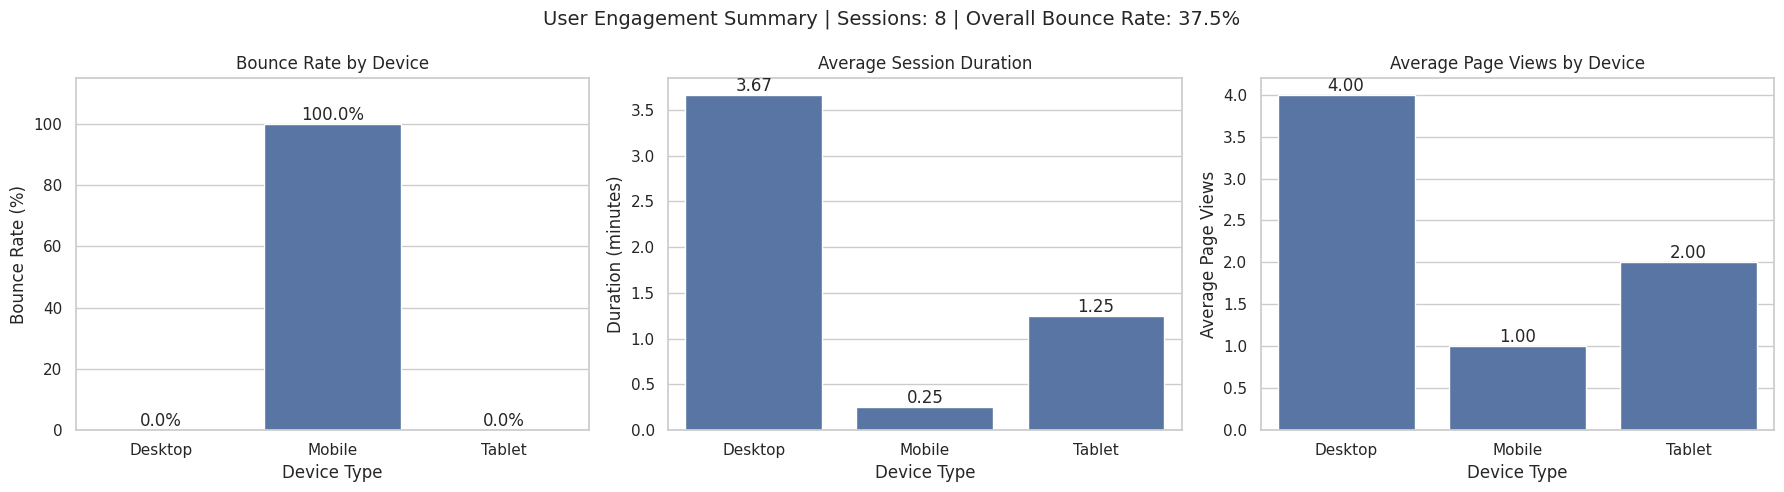

In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


def analyze_user_engagement(logs_df):
    """
    Analyze user engagement using one row per session.

    Required columns:
        session_id, page_views, session_start, session_end, device_type

    Returns:
        metrics: Overall engagement metrics dictionary.
        device_metrics: Engagement metrics grouped by device.
        session_data: Copy of the data with calculated session durations.
    """

    # 1. Validate input
    if not isinstance(logs_df, pd.DataFrame):
        raise TypeError("logs_df must be a pandas DataFrame.")

    if logs_df.empty:
        raise ValueError("logs_df cannot be empty.")

    # Reject blank or non-string column names.
    if not all(
        isinstance(col, str) and col.strip()
        for col in logs_df.columns
    ):
        raise ValueError("Column names must be non-empty strings.")

    required_columns = [
        "session_id",
        "page_views",
        "session_start",
        "session_end",
        "device_type"
    ]

    missing = [col for col in required_columns if col not in logs_df]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    # Work on a copy so the original data is unchanged.
    session_data = logs_df[required_columns].copy()

    if session_data.isnull().any().any():
        raise ValueError("Required columns cannot contain missing values.")

    # Validate session IDs.
    if session_data["session_id"].map(
        lambda x: isinstance(x, str) and not x.strip()
    ).any():
        raise ValueError("session_id cannot contain blank strings.")

    if session_data["session_id"].duplicated().any():
        raise ValueError("Each session_id must be unique.")

    # Reject Boolean page-view values explicitly.
    if session_data["page_views"].map(
        lambda x: isinstance(x, (bool, np.bool_))
    ).any():
        raise ValueError("page_views cannot contain Boolean values.")

    # Validate page-view counts.
    try:
        session_data["page_views"] = pd.to_numeric(
            session_data["page_views"], errors="raise"
        )
    except (TypeError, ValueError) as error:
        raise ValueError(
            "page_views must contain positive whole numbers."
        ) from error

    if not np.isfinite(session_data["page_views"]).all():
        raise ValueError("page_views must contain finite numbers.")

    if (
        (session_data["page_views"] < 1).any()
        or not session_data["page_views"].mod(1).eq(0).all()
    ):
        raise ValueError("page_views must contain positive whole numbers.")

    # Validate device names.
    if not session_data["device_type"].map(
        lambda x: isinstance(x, str) and bool(x.strip())
    ).all():
        raise ValueError("device_type must contain non-empty strings.")

    # 2. Parse timestamps.
    # utc=True handles timestamps with different timezone offsets
    # consistently. Naive timestamps are interpreted as UTC.
    for column in ["session_start", "session_end"]:
        try:
            session_data[column] = pd.to_datetime(
                session_data[column],
                errors="raise",
                utc=True
            )
        except (TypeError, ValueError) as error:
            raise ValueError(
                f"{column} must contain valid timestamps."
            ) from error

    # 3. Calculate duration from the actual start and end times.
    session_data["session_time"] = (
        session_data["session_end"] - session_data["session_start"]
    ).dt.total_seconds()

    if not np.isfinite(session_data["session_time"]).all():
        raise ValueError("Session durations must be finite.")

    if (session_data["session_time"] < 0).any():
        raise ValueError(
            "session_end cannot be earlier than session_start."
        )

    # 4. Calculate overall metrics.
    bounce_rate = session_data["page_views"].eq(1).mean()

    metrics = {
        "total_sessions": int(session_data["session_id"].nunique()),
        "bounce_rate": float(bounce_rate),
        "bounce_rate_percent": float(bounce_rate * 100),
        "avg_session_time_seconds": float(
            session_data["session_time"].mean()
        ),
        "avg_session_time_minutes": float(
            session_data["session_time"].mean() / 60
        ),
        "avg_page_views": float(session_data["page_views"].mean()),
        "total_page_views": int(session_data["page_views"].sum())
    }

    # 5. Calculate device-level metrics.
    device_metrics = (
        session_data.groupby("device_type")
        .agg(
            total_sessions=("session_id", "nunique"),
            bounce_rate=(
                "page_views",
                lambda values: values.eq(1).mean()
            ),
            avg_session_time_seconds=("session_time", "mean"),
            avg_page_views=("page_views", "mean"),
            total_page_views=("page_views", "sum")
        )
        .reset_index()
    )

    device_metrics["bounce_rate_percent"] = (
        device_metrics["bounce_rate"] * 100
    )

    # Round for readability while preserving full precision in metrics.
    round_columns = [
        "bounce_rate",
        "bounce_rate_percent",
        "avg_session_time_seconds",
        "avg_page_views"
    ]

    device_metrics[round_columns] = (
        device_metrics[round_columns].round(2)
    )

    return metrics, device_metrics, session_data


def plot_engagement_summary(metrics, device_metrics):
    """Create three summary visualizations."""

    sns.set_theme(style="whitegrid")

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Chart 1: Bounce rate by device.
    sns.barplot(
        data=device_metrics,
        x="device_type",
        y="bounce_rate_percent",
        ax=axes[0]
    )
    axes[0].set_title("Bounce Rate by Device")
    axes[0].set_xlabel("Device Type")
    axes[0].set_ylabel("Bounce Rate (%)")
    axes[0].set_ylim(0, 115)

    for container in axes[0].containers:
        axes[0].bar_label(container, fmt="%.1f%%")

    # Chart 2: Average session duration by device.
    duration_plot = device_metrics.copy()
    duration_plot["avg_session_time_minutes"] = (
        duration_plot["avg_session_time_seconds"] / 60
    )

    sns.barplot(
        data=duration_plot,
        x="device_type",
        y="avg_session_time_minutes",
        ax=axes[1]
    )
    axes[1].set_title("Average Session Duration")
    axes[1].set_xlabel("Device Type")
    axes[1].set_ylabel("Duration (minutes)")

    for container in axes[1].containers:
        axes[1].bar_label(container, fmt="%.2f")

    # Chart 3: Average page views by device.
    sns.barplot(
        data=device_metrics,
        x="device_type",
        y="avg_page_views",
        ax=axes[2]
    )
    axes[2].set_title("Average Page Views by Device")
    axes[2].set_xlabel("Device Type")
    axes[2].set_ylabel("Average Page Views")

    for container in axes[2].containers:
        axes[2].bar_label(container, fmt="%.2f")

    fig.suptitle(
        f"User Engagement Summary | "
        f"Sessions: {metrics['total_sessions']} | "
        f"Overall Bounce Rate: {metrics['bounce_rate_percent']:.1f}%",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()


# --------------------------------------------------
# Sample data: one row per session
# --------------------------------------------------

logs_df = pd.DataFrame({
    "session_id": [101, 102, 103, 104, 105, 106, 107, 108],
    "page_views": [1, 3, 1, 5, 2, 1, 4, 2],
    "session_start": [
        "2026-10-20 09:00:00",
        "2026-10-20 09:10:00",
        "2026-10-20 09:20:00",
        "2026-10-20 09:30:00",
        "2026-10-20 09:40:00",
        "2026-10-20 09:50:00",
        "2026-10-20 10:00:00",
        "2026-10-20 10:10:00"
    ],
    "session_end": [
        "2026-10-20 09:00:15",
        "2026-10-20 09:12:00",
        "2026-10-20 09:20:10",
        "2026-10-20 09:35:00",
        "2026-10-20 09:41:30",
        "2026-10-20 09:50:20",
        "2026-10-20 10:04:00",
        "2026-10-20 10:11:00"
    ],
    "device_type": [
        "Mobile", "Desktop", "Mobile", "Desktop",
        "Tablet", "Mobile", "Desktop", "Tablet"
    ]
})


# --------------------------------------------------
# Run the analysis and display results
# --------------------------------------------------

if __name__ == "__main__":
    try:
        metrics, device_metrics, session_data = (
            analyze_user_engagement(logs_df)
        )

        print("SAMPLE DATA WITH CALCULATED DURATIONS")
        print(
            session_data[
                [
                    "session_id",
                    "device_type",
                    "session_time",
                    "page_views"
                ]
            ].to_string(index=False)
        )

        print("\nOVERALL ENGAGEMENT METRICS")
        for metric, value in metrics.items():
            if metric == "bounce_rate_percent":
                print(f"{metric}: {value:.1f}%")
            elif metric == "avg_session_time_minutes":
                print(f"{metric}: {value:.2f} minutes")
            elif metric == "avg_session_time_seconds":
                print(f"{metric}: {value:.2f} seconds")
            elif isinstance(value, float):
                print(f"{metric}: {value:.2f}")
            else:
                print(f"{metric}: {value}")

        print("\nENGAGEMENT BY DEVICE")
        print(device_metrics.to_string(index=False))

        # Display summary charts.
        plot_engagement_summary(metrics, device_metrics)

    except (TypeError, ValueError) as error:
        print(f"Analysis error: {error}")
